# Four groups for ANOVA

Synthetic dataset to use in ANOVA and LMs with categorical predictor.

In [1]:
datafilepath = "../datasets/fourgroups.csv"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Construct data as a pd.DataFrame
n = 20
from scipy.stats import norm

np.random.seed(42)
Avalues = norm(0,1).rvs(n)
Bvalues = norm(-2,1).rvs(n)
Cvalues = norm(3,1).rvs(n)
Dvalues = norm(1.5,1).rvs(n)

fourgroups = pd.DataFrame()
fourgroups["group"] = ["A"]*n + ["B"]*n + ["C"]*n + ["D"]*n
allvalues = [Avalues, Bvalues, Cvalues, Dvalues]
values = np.concatenate(allvalues)
fourgroups["value"] = values.round(3)
fourgroups

,group,value
0,A,0.497
1,A,-0.138
2,A,0.648
3,A,1.523
4,A,-0.234
...,...,...
75,D,2.322
76,D,1.587
77,D,1.201
78,D,1.592


In [4]:
# # SAVE TO DATAFILE
# fourgroups.to_csv(datafilepath, index=False)

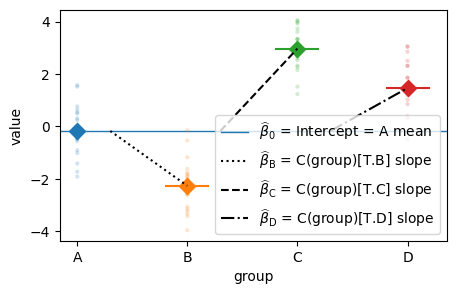

In [5]:
# @solution
from ministats.plots.figures import plot_lm_anova
plot_lm_anova(fourgroups, x="group", y="value");

In [6]:
# @solution
import statsmodels.formula.api as smf
lmABCD =  smf.ols("value ~ 1 + C(group)", data=fourgroups).fit()
lmABCD.fvalue, lmABCD.f_pvalue

(np.float64(107.21521845087047), np.float64(3.1038823501963045e-27))

In [7]:
# @solution
from scipy.stats import f_oneway
resABCD = f_oneway(Avalues, Bvalues, Cvalues, Dvalues)
resABCD.statistic, resABCD.pvalue

(np.float64(107.22963883851017), np.float64(3.091116115443279e-27))

<!-- @solution -->
